In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp
from scipy.linalg import solve_banded

In [2]:
Lx = np.pi
Ly = 2.0
Lz = np.pi
nx = 64
ny = 64
nz = 64
dx = Lx / nx
dy = Ly / (ny - 1)  # change to non uniform later
ds = 1.0 / (ny - 1)
dz = Lz / nz
kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
m = np.arange(ny)
kz = 2 * np.pi * np.fft.fftfreq(nz, dz)

In [3]:
x = np.linspace(0, Lx, nx, endpoint=False)
y = np.linspace(0, Ly, ny)
z = np.linspace(0, Lz, nz, endpoint=False)

In [4]:
X, Y, Z = np.meshgrid(x, y, z, indexing="ij")

In [5]:
pressure = np.cos(X) * np.cos(Y) * np.cos(Z)

In [6]:
rhs = -3 * pressure

In [7]:
rhshatxz = np.fft.fftn(rhs, axes=(0, 2))
rhshat = scp.fft.dct(rhshatxz, axis=1, type=1)

In [8]:
def compute_alpha(b):
    return (np.sqrt(1 + 4 * np.pi * np.pi * b * b) - 1) / 2 * b

In [9]:
beta = 0.259065151
alpha = compute_alpha(beta)
gamma = 1
delta = 1/2

In [10]:
alpha

np.float64(0.11792496725301939)

In [11]:
# mk for modified k wave number
amk = 1/3
bmk = 14/9
alphamk = 1/9

In [12]:
# k prime l
def modified_wavenumber(k, d):
    return (amk * np.sin(k * d) + (bmk / 2) * np.sin(2 * k * d)) / (1 + 2 * alphamk * np.cos(k * d)) * 1/d
kpl = modified_wavenumber(kx, dx)
km = np.pi * m
kpm = modified_wavenumber(km, ds)
kpn = modified_wavenumber(kz, dz)

In [13]:
# nabla operator
lambda_ = -kpl[:, None, None]**2 - kpm[None, :, None]**2 - kpn[None, None, :]**2

In [49]:
a0 = 1/(np.pi * Ly) * (alpha + 1 / (2 * beta))
a1 = 1 / (4 * np.pi * beta * Ly)
# a1 = a-1
am1 = a1

def build_nabla_operator(kpm, kl, kn):
    ny = kpm.shape[0]
    A = np.zeros((5, ny))
    
    # A[0,  2:] -> kmm = 0:-2; kmm+1 = 1:-1; kmm+2 = 2:
    # A[1,  1:] -> kmm = 0:-1; kmm+1 = 1:
    # A[2,   1:-1] -> kmm =  :; kmm+1 = 1: ;  kmm-1 = :-1
    # A[3, :-1] -> kmm = 1:; kmm-1 = :-1
    # A[4, :-2] -> kmm = 2:; kmm-1 = 1:-1; kmm-2 = :-2
    A[0, 2:] = -a1 * a1 * kpm[1:-1] * kpm[0:-2]  # kmm = 0:-2
    A[1, 1:] = -a0 * a1 * kpm[1:] * (kpm[0:-1] + kpm[1:])
    A[2, :] = -kl** 2 - kn** 2  - a0*a0 * kpm[:]*kpm[:] - a1 * am1 * kpm[:] * (np.r_[0, kpm[:-1]] + np.r_[kpm[1:], 0])
    A[3, :-1] = -a0 * am1 * kpm[:-1] * (kpm[1:] + kpm[:-1])
    A[4, :-2] = -am1 * am1 * kpm[1:-1] * kpm[:-2]
    
    return A
    

In [50]:
a1

0.15358582819567979

In [51]:
epsilon = 1e-5
phat = np.zeros_like(rhshat)
for ikx in range(nx):
    for ikz in range(nz):
        kl = kpl[ikx]
        kn = kpn[ikz]
        K = -(kl ** 2 + kn ** 2)
        if abs(K) < epsilon:
            print(f"skipping mode ({ikx}, {ikz}) K=[{K}]")
            continue
        A = build_nabla_operator(kpm, kl, kn)
        phat[ikx, :, ikz] = solve_banded((2, 2), A, rhshat[ikx, :, ikz])

skipping mode (0, 0) K=[-0.0]
skipping mode (0, 32) K=[-1.5369905464947305e-29]
skipping mode (32, 0) K=[-1.5369905464947305e-29]
skipping mode (32, 32) K=[-3.073981092989461e-29]


In [52]:
phaty = scp.fft.idct(phat, axis=1, type=1)
p = np.fft.ifftn(phaty, axes=(0, 2))

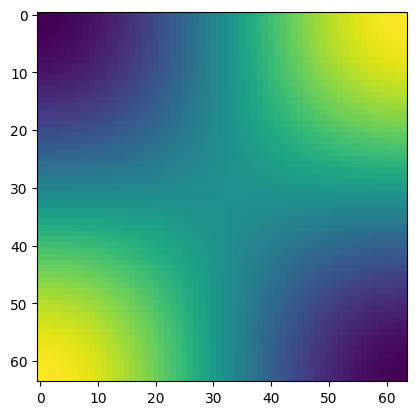

In [53]:
plt.imshow(rhs[:, 32, :])
plt.show()

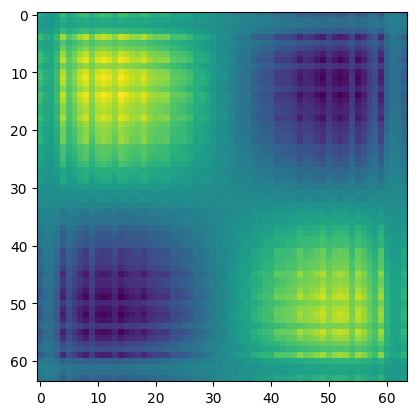

In [54]:
plt.imshow(p.real[:, 32, :])
plt.show()

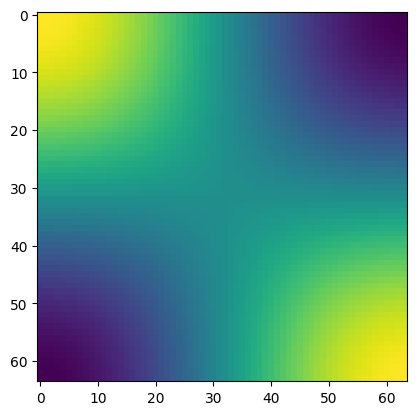

In [55]:
plt.imshow(pressure[:, 32, :])
plt.show()

In [56]:
def rmse(X, Y):
    return np.linalg.norm(X - Y) / np.linalg.norm(Y)

In [57]:
rmse(p, pressure)

np.float64(0.9053455380173787)

In [58]:
print("kpm[0] =", kpm[0])
print("kpm[-1] =", kpm[-1])
print("ds =", ds)

kpm[0] = 0.0
kpm[-1] = -1.2124003311558799e-14
ds = 0.015873015873015872
